# 5주차 ② FashionMNIST MLP — 실습 5~12  〔교수용 정답본〕

> ⚠️ **이 파일은 교수용입니다.** 학생에게는 `07_mlp_fashionmnist_blank.ipynb` 를 배포하세요.
> 빈칸 12곳 · 27줄이 모두 채워져 있습니다.

---

## 실습 5 — 돌리기 전에 입력의 크기를 맞춘다

옷 사진은 픽셀값이 0~255 입니다. `ToTensor()` 가 0~1 로 바꿔 주지만 **그것으로는 부족**합니다.
학습이 시작될 때 **입력의 크기를 고르게 맞춰 주면** 훨씬 매끄럽게 내려갑니다.

`transforms.Normalize` 가 그 일을 합니다. 통계에서 배운 **표준화**와 같은 것이니
새 개념이 아닙니다 — **숫자로 직접 확인**해 봅시다.

In [28]:
# 셀 1 — 준비와 데이터 내려받기
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

from fashion_labels import LABELS, setup_korean_font, show_grid, wrong_titles, name
setup_korean_font()

ROOT = "data"          # ★ 공유 폴더를 쓴다면 그 경로로 바꾸세요

plain = transforms.ToTensor()          # 0~255 를 0~1 로 바꾸기만 한다

norm = transforms.Compose([transforms.ToTensor(),
                           transforms.Normalize((0.2860,), (0.3530,))])
train_norm = datasets.FashionMNIST(ROOT, train=True, download=True, transform=norm)

train_plain = datasets.FashionMNIST(ROOT, train=True, download=True, transform=plain)
test_norm = datasets.FashionMNIST(ROOT, train=False, download=True, transform=norm)

print("학습", len(train_norm), "장 / 테스트", len(test_norm), "장")

학습 60000 장 / 테스트 10000 장


> ⚠️ **다운로드가 시작되면 그대로 두세요** (약 30MB). 공유 폴더의 `data/` 를 쓰면 0초입니다.
>
> ⚠️ **`.gitignore` 에 `data/` 를 지금 추가하세요** — 2주차에 배운 것을 처음으로 실제로 쓰는 순간입니다.
> 데이터셋을 커밋하면 저장소가 부풀어 학기 내내 고생합니다.

In [29]:
# 셀 2 — 정규화는 무엇을 바꾸나 (그림 2000장으로 확인)
def stats(dataset, n=2000):
    xs = torch.stack([dataset[i][0] for i in range(n)])
    return xs.mean().item(), xs.std().item()


m0, s0 = stats(train_plain)
m1, s1 = stats(train_norm)

print(f"정규화 전 (ToTensor 만) | 평균 {m0:6.3f} | 표준편차 {s0:6.3f}")
print(f"정규화 후 (Normalize)   | 평균 {m1:6.3f} | 표준편차 {s1:6.3f}")

정규화 전 (ToTensor 만) | 평균  0.284 | 표준편차  0.354
정규화 후 (Normalize)   | 평균 -0.006 | 표준편차  1.001


> **관찰 포인트 ★**
>
> | | 평균 | 표준편차 |
> |---|---|---|
> | 정규화 전 (`ToTensor` 만) | 0.284 | 0.354 |
> | 정규화 후 (`Normalize`) | **-0.006** | **1.001** |
>
> 하는 일은 딱 하나입니다 — **평균을 0 근처로 옮기고, 흩어진 정도를 1 근처로 맞춘다.**
> 입력이 이렇게 정리되면 학습이 한쪽으로 치우쳐 흔들리는 일이 줄어듭니다.

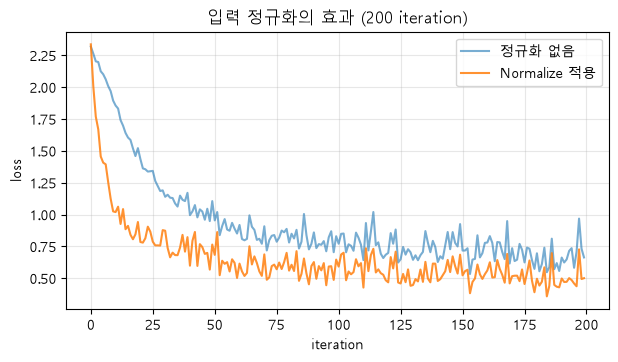

마지막 50 iteration 학습 손실 평균 | 정규화 없음 0.6936 | Normalize 0.5143


In [30]:
# 셀 3 — 정규화가 학습에 실제로 도움이 되나 (200 iteration 만 돌려 비교)
def quick_train(dataset, iters=200, lr=0.1):
    torch.manual_seed(0)
    loader = DataLoader(dataset, batch_size=128, shuffle=True)
    model = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()

    hist = []
    for i, (xb, yb) in enumerate(loader):
        loss = loss_fn(model(xb), yb)
        opt.zero_grad()
        loss.backward()
        opt.step()
        hist.append(loss.item())
        if i + 1 == iters:
            break
    return hist


h_plain = quick_train(train_plain)
h_norm = quick_train(train_norm)

plt.figure(figsize=(7, 3.6))
plt.plot(h_plain, label="정규화 없음", alpha=0.6)
plt.plot(h_norm, label="Normalize 적용", alpha=0.85)
plt.xlabel("iteration"); plt.ylabel("loss"); plt.legend()
plt.title("입력 정규화의 효과 (200 iteration)"); plt.grid(alpha=0.3)
plt.show()

print(f"마지막 50 iteration 학습 손실 평균 | 정규화 없음 {sum(h_plain[-50:])/50:.4f}"
      f" | Normalize {sum(h_norm[-50:])/50:.4f}")

> **관찰 포인트 ★**: 정규화한 쪽이 **더 빨리, 더 매끄럽게** 내려갑니다.
>
> ```
> 마지막 50 iteration 학습 손실 평균 | 정규화 없음 0.694 | Normalize 0.514
> ```
>
> 200 iteration 만 돌렸는데도 **0.69 대 0.51** 입니다. 같은 모델, 같은 학습률,
> 같은 데이터인데 **입력의 크기를 맞췄다는 것 하나로** 생긴 차이입니다.
> 층이 깊어지고 문제가 어려워질수록 이 차이는 더 벌어집니다.

---

## 실습 6 — 가중치의 출발값 ★

학습을 시작할 때 가중치는 **어떤 값에서 출발**할까요? 세 가지를 비교합니다.

| 출발값 | 무슨 일이 벌어지나 |
|---|---|
| **전부 0** | ? |
| **너무 큰 무작위** | ? |
| **He 초기화** | ? |

외울 것은 짝 하나뿐입니다 — **ReLU 에는 He, Sigmoid·Tanh 에는 Xavier.** (Tanh 는 10주차에 배우는 활성함수입니다.)
나머지는 아래 숫자가 설명해 줍니다.

In [31]:
# 셀 4 — 출발값을 세 가지로 바꿔 본다
def make_model(kind):
    torch.manual_seed(0)
    m = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
    for layer in m:
        if isinstance(layer, nn.Linear):
            if kind == "zero": nn.init.zeros_(layer.weight)
            elif kind == "big": nn.init.normal_(layer.weight, mean=0.0, std=1.0)
            elif kind == "he": nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
    return m


print(f"{'출발값':>6} | {'첫 층 weight 의 std':>20}")
print("-" * 32)
for kind in ["zero", "big", "he"]:
    print(f"{kind:>6} | {make_model(kind)[1].weight.std().item():>20.4f}")

   출발값 |     첫 층 weight 의 std
--------------------------------
  zero |               0.0000
   big |               1.0048
    he |               0.0508


In [32]:
# 셀 5 — 그래서 학습이 어떻게 달라지나 (100 iteration 만)
loader = DataLoader(train_norm, batch_size=128, shuffle=True)
loss_fn = nn.CrossEntropyLoss()

print(f"{'출발값':>6} | {'첫 loss':>9} | {'100번째 loss':>13}")
print("-" * 36)
for kind in ["zero", "big", "he"]:
    torch.manual_seed(0)
    model = make_model(kind)
    opt = torch.optim.SGD(model.parameters(), lr=0.1)
    losses = []
    for i, (xb, yb) in enumerate(loader):
        loss = loss_fn(model(xb), yb)
        opt.zero_grad()
        loss.backward()
        opt.step()
        losses.append(loss.item())
        if i == 99:
            break
    print(f"{kind:>6} | {losses[0]:>9.4f} | {losses[-1]:>13.4f}")

   출발값 |    첫 loss |    100번째 loss
------------------------------------
  zero |    2.3026 |        2.3022
   big |  277.8453 |       10.5951
    he |    2.7975 |        0.4679


In [33]:
# 셀 6 — 0 으로 시작하면 왜 안 되나 (뉴런을 직접 들여다본다)
xb, yb = next(iter(loader))

m_zero = make_model("zero")
h_zero = m_zero[1](m_zero[0](xb))          # Flatten -> 첫 Linear
print("0 초기화  | 첫 층 뉴런 5개 :", [round(v, 4) for v in h_zero[0, :5].tolist()])

m_he = make_model("he")
h_he = m_he[1](m_he[0](xb))
print("He 초기화 | 첫 층 뉴런 5개 :", [round(v, 4) for v in h_he[0, :5].tolist()])

0 초기화  | 첫 층 뉴런 5개 : [0.0, 0.0, 0.0, 0.0, 0.0]
He 초기화 | 첫 층 뉴런 5개 : [1.4664, 1.1591, 2.5914, -0.9634, 3.0308]


> **결과 해석 ★★ (중간고사 출제 지점)**
>
> | 출발값 | weight 의 std | 100 iteration 뒤 손실 | 무슨 일이 |
> |---|---|---|---|
> | **전부 0** | 0.0000 | 2.3026 → **2.3022** | 뉴런들이 **전부 같은 값**을 내고 **똑같이 갱신**된다. 128개를 써도 1개짜리와 같다 ★ |
> | **너무 큰 무작위** | 1.0048 | 277.8 → **10.6** | 시작 손실이 엄청 높다. 그래도 내려오는 중 (발산은 아니다) |
> | **He** | 0.0508 | 2.7975 → **0.4679** | 혼자만 제대로 내려갔다 ★ |
>
> 마지막 셀의 출력을 보세요. **0 초기화에서는 뉴런 5개가 전부 같은 값** 입니다.
> He 초기화에서는 제각각입니다. 이것이 *"0 으로 초기화하면 안 되는 이유"* 입니다.
>
> **손실 2.30 이 무슨 뜻인가**: 10개 중 하나를 완전히 찍을 때 나오는 값입니다.
> (1교시 XOR 에서 본 0.693 과 같은 성격의 숫자 — *"아무것도 모른다"*.)

> **참고 ★**: `nn.Linear` 는 **아무것도 안 해도 나름의 초기화를 이미 하고 있습니다.**
> 그래서 4주차에 신경 쓰지 않아도 잘 됐던 것입니다.
> 다만 그 기본값이 **He 는 아닙니다** — 자세한 것은 `📘 이론 보충` 에 있습니다.

---

## 실습 7 — 모델을 클래스로 묶는다

지금까지는 `nn.Sequential` 로 충분했습니다. 그런데 모델이 커지고,
*"입력을 펴고 → 층을 통과시키고 → 중간 결과도 꺼내 보고"* 같은 일이 생기면
**클래스로 묶는 편**이 낫습니다. 그것이 `nn.Module` 입니다.

| 메서드 | 하는 일 |
|---|---|
| `__init__` | **부품을 준비한다** (층을 만들어 self 에 붙인다) |
| `forward` | **부품을 순서대로 통과시킨다** (데이터가 흘러가는 길) |

> **주의**: `forward` 를 직접 부르지 않습니다. `model(x)` 라고 쓰면 PyTorch 가 알아서 부릅니다.

In [34]:
# 셀 7 — MLP 정의 : 784 -> 256 -> 128 -> 10
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()          # (N,1,28,28) -> (N,784)
        self.net = nn.Sequential(
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 10),              # ★ 여기에 Softmax 를 붙이지 않는다 (실습 4 함정 2)
        )

    def forward(self, x):
        return self.net(self.flatten(x))


model = MLP()
print(model)

total = sum(p.numel() for p in model.parameters())
print("\n파라미터 수 :", f"{total:,} 개")

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

파라미터 수 : 235,146 개


In [35]:
# 셀 8 — 학습 전에 가짜 입력으로 shape 을 검산한다
fake = torch.randn(4, 1, 28, 28)         # 배치 4장짜리 가짜 이미지
out = model(fake)
print("입력 :", tuple(fake.shape), " ->  출력 :", tuple(out.shape))
print("출력 한 줄 :", [round(v, 3) for v in out[0].tolist()])

입력 : (4, 1, 28, 28)  ->  출력 : (4, 10)
출력 한 줄 : [-0.071, -0.13, 0.143, 0.055, -0.239, -0.063, -0.005, -0.23, -0.226, -0.061]


> **관찰 포인트 ★**: 파라미터가 **235,146 개**입니다. 4주차에는 **2개**였습니다.
> 이만한 수를 손으로 갱신할 수는 없습니다 — 그래서 `optimizer` 가 필요합니다.
>
> **모델을 만들면 학습 전에 가짜 입력으로 shape 을 먼저 확인하세요.**
> `(4,1,28,28)` 을 넣어 `(4,10)` 이 나오면 배선이 맞은 것입니다.
> 본격적으로 학습을 돌리기 전에 가짜 입력 몇 장으로 shape 을 먼저 확인해 두면, 학습 도중에 날 오류를 미리 잡을 수 있습니다.
>
> 출력 10개는 **확률이 아닙니다** — 아직 Softmax 를 안 씌운 **날것(logits)** 입니다.

---

## 실습 8 — 6만 장을 조각내 흘려보낸다

6만 장을 한 번에 넣을 수 없습니다. **조각(배치)** 으로 나눠 흘립니다.
`DataLoader` 가 그 통로입니다.

| 용어 | 뜻 |
|---|---|
| **batch** | 한 번에 넣는 묶음 (우리는 128장) |
| **iteration** | 배치 하나를 처리하는 것 = 갱신 1회 |
| **epoch** | 6만 장을 **한 바퀴** 다 본 것 |

> **미니배치를 쓰는 이유 두 가지** (출제 지점): ① 메모리에 다 안 들어간다
> ② 한 바퀴에 갱신을 **469번** 할 수 있다 (통째로 넣으면 1번)

In [36]:
# 셀 9 — DataLoader 만들기
BATCH = 128
train_loader = DataLoader(train_norm, batch_size=BATCH, shuffle=True)
test_loader = DataLoader(test_norm, batch_size=BATCH, shuffle=False)

print("1 epoch 의 배치 수 :", len(train_loader), "(학습) /", len(test_loader), "(테스트)")

xb, yb = next(iter(train_loader))
print("x shape :", tuple(xb.shape), " | y shape :", tuple(yb.shape))
print("y 앞 8개 :", yb[:8].tolist(), "  ← 클래스 번호")

1 epoch 의 배치 수 : 469 (학습) / 79 (테스트)
x shape : (128, 1, 28, 28)  | y shape : (128,)
y 앞 8개 : [8, 4, 6, 1, 5, 5, 7, 1]   ← 클래스 번호


> **관찰 포인트 ★**: `len(train_loader)` 가 **469** 입니다.
> 6만 장을 128장씩 나누면 468.75 → 마지막 조각이 작게 남아 **469** 개가 됩니다.
> *(이 숫자가 왜 469인지 설명할 수 있어야 합니다 — 출제 지점)*
>
> `y` 의 shape 이 `(128,)` 인 것도 확인하세요. **클래스 번호 128개**입니다.

In [ ]:
# 셀 10 — 우리가 맞혀야 할 것을 눈으로 본다
show_grid(xb[:9], [name(t) for t in yb[:9].tolist()], ncols=3)

> **관찰 포인트**: **셔츠 · 코트 · 풀오버**는 사람 눈으로도 헷갈립니다.
> 28×28 흑백이라 단추나 옷깃 같은 단서가 거의 없습니다.
> 이따가 모델이 틀리는 것도 **정확히 이 세 가지**입니다 (실습 11).

---

# 3교시

## 실습 9 — 학습 루프를 쓰고 끝까지 돌린다 ★★

**오늘의 하이라이트입니다.** 준비는 다 됐습니다.

| 준비된 것 | |
|---|---|
| 모델 | `MLP()` — 784→256→128→10, 파라미터 235,146개 |
| 데이터 통로 | `train_loader` (469 배치), `test_loader` (79 배치) |
| 손실 | `nn.CrossEntropyLoss()` |
| 옵티마이저 | 지금 만든다 |

### 4주차와 무엇이 다른가

```
[4주차]                                  [5주차 = 오늘]

for epoch in range(200):                 for epoch in range(EPOCHS):
                                             for xb, yb in train_loader:   ← ★ 이 줄만 추가
    pred = model(x)                              pred = model(xb)
    loss = loss_fn(pred, y)                      loss = loss_fn(pred, yb)
    optimizer.zero_grad()                        optimizer.zero_grad()
    loss.backward()                              loss.backward()
    optimizer.step()                             optimizer.step()
```

### 옵티마이저 — 23만 개를 누가 고치나 ★

셀 11 에 **4주차 3교시에 이미 썼던 한 줄**이 있습니다. 그때는 `w`, `b` 몇 개를 고쳤고, 오늘은 같은 줄이 23만 개를 고칩니다. 2교시에 *"`nn.Module` 이 파라미터를 모아 주니
옵티마이저에 한 줄로 넘길 수 있다"* 고 했던 그 줄입니다.

```python
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
#                       ↑              ↑           ↑
#                  어떻게 고칠까   무엇을 고칠까  얼마씩 고칠까
```

| 조각 | 뜻 |
|---|---|
| `SGD` | **S**tochastic **G**radient **D**escent = **확률적 경사하강법**. ④역전파가 구한 기울기의 **반대 방향**으로 한 걸음 내려간다 |
| `model.parameters()` | 고칠 대상 **235,146개**. 2교시에 `nn.Module` 이 모아 준 그 목록 |
| `lr=0.1` | 한 걸음의 크기(**학습률**). 4주차 `w -= lr * w.grad` 의 그 `lr` |

**`optimizer.step()` 한 줄이 하는 일은 `w = w − 0.1 × w.grad` 를 23만 개 전부에 대해** 입니다.
4주차에 손으로 썼던 그 식을 대신 해 주는 것이고, 식이 바뀐 것이 아니라
손으로 쓸 수 없을 만큼 많아져서 맡긴 것입니다.

**이름의 "확률적(Stochastic)" 은** 6만 장 전부가 아니라 **128장만 보고** 방향을 정한다는 뜻입니다.
방향이 조금 흔들리는 대신 1 epoch 에 **469걸음**을 걷습니다 — 2교시에 *"조각내면 훨씬 빨리 배운다"* 고
한 것이 이 이야기입니다. 그래서 손실이 매끄러운 직선이 아니라 **살짝 지그재그로** 내려갑니다.

> `lr` 은 정답이 없어서 경험으로 고르고 실험으로 확인합니다 — **실습 12에서 직접 0.5 와 0.01 로 바꿔 봅니다.**

---

**진짜로 안쪽 for 문 하나 차이입니다.** 4주차에는 데이터가 100건이라 통째로 넣었고,
오늘은 6만 장이라 469번에 나눠 넣습니다.

새로 붙는 것은 세 가지뿐입니다.

| 추가 | 코드 | 왜 |
|---|---|---|
| **장치 이동** | `xb.to(device)` | 모델이 GPU 에 있으면 데이터도 GPU 로 (3주차) |
| **모드 전환** | `model.train()` / `model.eval()` | 드롭아웃·배치정규화의 동작이 달라진다 |
| **에폭 요약** | `running += loss.item() * xb.size(0)`<br>`epoch_loss = running / n` | 배치 469개의 손실을 다 찍으면 화면이 넘친다 → **에폭마다 평균 1개만 출력** |

In [37]:
# 셀 11 — 장치 · 모델 · 손실 · 옵티마이저
device = "cuda" if torch.cuda.is_available() else "cpu"      # 3주차의 표준 2줄
print("사용할 장치 :", device)

model = MLP().to(device)                  # ★ 모델을 장치로
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

EPOCHS = 5                # CPU 로 약 3분 (epoch 당 35초). GPU 라면 10 으로 늘려도 좋습니다

사용할 장치 : cpu


In [38]:
# 셀 12 — 학습 루프  ★★ 오늘의 하이라이트
history = []

for epoch in range(EPOCHS):
    model.train()
    running, n = 0.0, 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)          # 장치로 (3주차)

        pred = model(xb)                               # ① 순전파
        loss = loss_fn(pred, yb)                       # ② 손실
        optimizer.zero_grad()                          # ③ 지우기
        loss.backward()                                # ④ 역전파
        optimizer.step()                               # ⑤ 갱신

        running += loss.item() * xb.size(0)            # 배치 평균 손실 × 장수 = 배치 손실 합
        n += xb.size(0)

    epoch_loss = running / n
    history.append(epoch_loss)
    print(f"epoch {epoch + 1}/{EPOCHS} | 평균 loss = {epoch_loss:.4f}")

print("\n학습 완료")

epoch 1/5 | 평균 loss = 0.5814
epoch 2/5 | 평균 loss = 0.3949
epoch 3/5 | 평균 loss = 0.3503
epoch 4/5 | 평균 loss = 0.3225
epoch 5/5 | 평균 loss = 0.3021

학습 완료


> **화면에서 손실이 한 줄씩 떨어지는 것을 끝까지 보세요.**
> *"내가 만든 모델이 6만 장을 보고 배우고 있다."* 이 장면이 오늘의 목적입니다.
>
> **막히면**
>
> | 증상 | 원인 |
> |---|---|
> | `Expected all tensors to be on the same device` | `.to(device)` 를 빼먹었다 (3주차 실습 8) |
> | 손실이 안 줄어든다 | 빈칸 ②에서 `zero_grad` 나 `step` 이 빠졌거나 순서가 틀렸다 |
> | `Expected input batch_size ... to match target` | `forward` 에서 `flatten` 을 빼먹었다 (실습 7) |
> | 손실이 `nan` | `lr` 이 크다. 0.1 → 0.01 로 |
> | `NameError: loss` | 빈칸 ②를 아직 안 채웠다 |
> | 아주 느리다 | `device` 가 `cpu` 다. 정상이며 `EPOCHS` 를 3으로 줄여도 된다 |

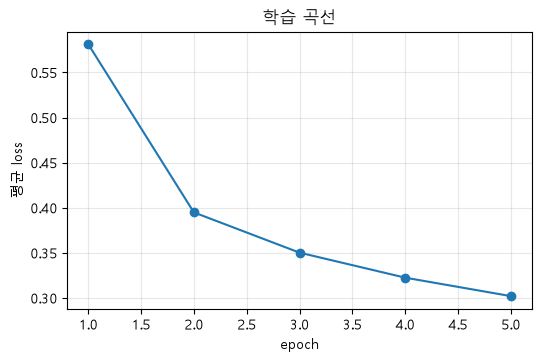

저장 완료 : models/mlp_fashion.pt


In [39]:
# 셀 13 — 학습 곡선과 가중치 저장
import os

plt.figure(figsize=(6, 3.6))
plt.plot(range(1, len(history) + 1), history, marker="o")
plt.xlabel("epoch"); plt.ylabel("평균 loss"); plt.title("학습 곡선")
plt.grid(alpha=0.3)
plt.show()

os.makedirs("models", exist_ok=True)
torch.save(model.state_dict(), "models/mlp_fashion.pt")
print("저장 완료 : models/mlp_fashion.pt")

> **포인트 ★**: `state_dict()` 는 **가중치만** 저장합니다. 모델의 구조는 코드(`class MLP`)가
> 갖고 있습니다. 6주차에 이 파일을 다시 불러와 씁니다.
>
> ⚠️ **`models/` 도 `.gitignore` 에 넣으세요.**

---

## 실습 10 — 얼마나 맞히나

학습에 쓰지 않은 **테스트 1만 장**으로 채점합니다. 평가할 때는 두 가지를 씁니다.

| | 하는 일 |
|---|---|
| `model.eval()` | 층의 **동작 모드**를 평가용으로 바꾼다 |
| `torch.no_grad()` | **기울기 계산을 안 한다** (메모리·속도) |

> **둘은 다른 것입니다** (출제 지점). 평가할 때는 **둘 다** 씁니다.
> 지금 우리 MLP 에는 드롭아웃도 배치정규화도 없어서 `eval()` 이 바꾸는 게 없지만,
> **6주차에 드롭아웃을 넣는 순간 반드시 필요**해집니다. 습관을 지금 들입니다.

In [40]:
# 셀 14 — 테스트 정확도
model.eval()

correct, total_n = 0, 0

with torch.no_grad():                                  # ★ 그래프를 그리지 않는다
    for xb, yb in test_loader:
        xb, yb = xb.to(device), yb.to(device)

        pred = model(xb).argmax(dim=1)
        correct += (pred == yb).sum().item()
        total_n += yb.size(0)

print(f"테스트 정확도 : {100 * correct / total_n:.2f}%   ({correct} / {total_n})")

테스트 정확도 : 86.20%   (8620 / 10000)


> **관찰 포인트 ★**: **85% 내외**면 정상입니다 (교수님 PC 실측 **86.20%**).
> 10개 중 하나를 찍으면 10% 이므로, 모델이 확실히 무언가를 배웠습니다.
>
> **이 숫자를 적어 두세요.** 실습 12 에서 비교합니다.

In [41]:
# 셀 15 — 한 장을 확률로 들여다본다
img, label = test_norm[0]

model.eval()
with torch.no_grad():
    prob = torch.softmax(model(img.unsqueeze(0).to(device)), dim=1).squeeze()

top3 = prob.topk(3)
print("정답 :", name(label), "\n")
print("모델이 생각한 상위 3개")
for p, i in zip(top3.values.tolist(), top3.indices.tolist()):
    print(f"  {name(i):8s} {p * 100:5.1f}%")

정답 : 앵클부츠 

모델이 생각한 상위 3개
  앵클부츠      91.4%
  샌들         6.8%
  스니커즈       1.8%


> **관찰 포인트**: 여기서 비로소 `torch.softmax` 를 씁니다.
> 학습할 때는 안 씌웠습니다 (실습 4 함정 2). **사람이 확률로 보고 싶을 때만** 씌웁니다.
>
> 상위 3개를 보면 **모델이 무엇과 헷갈렸는지** 보입니다.

---

## 실습 11 — 틀린 것을 직접 본다

정확도 85% 라는 것은 **1500장을 틀렸다**는 뜻이기도 합니다.
숫자만 보지 말고 **무엇을 틀렸는지** 봅시다. 여기서 다음 주차의 동기가 나옵니다.

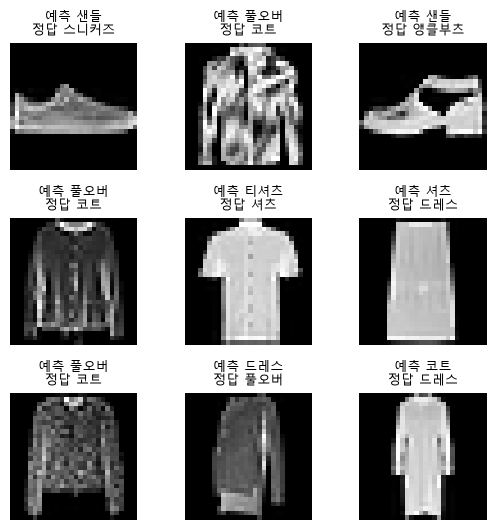

In [42]:
# 셀 16 — 틀린 것만 모아 본다
model.eval()
wrong_img, wrong_pred, wrong_true = [], [], []

with torch.no_grad():
    for xb, yb in test_loader:
        out = model(xb.to(device)).argmax(dim=1).cpu()

        mask = out != yb
        wrong_img.extend(xb[mask])

        wrong_pred.extend(out[mask].tolist())
        wrong_true.extend(yb[mask].tolist())
        if len(wrong_img) >= 9:
            break

show_grid(wrong_img[:9], wrong_titles(wrong_pred[:9], wrong_true[:9]), ncols=3)

In [43]:
# 셀 17 — 어떤 클래스에서 가장 많이 틀리나
from collections import Counter

model.eval()
pairs = []
with torch.no_grad():
    for xb, yb in test_loader:
        out = model(xb.to(device)).argmax(dim=1).cpu()
        for p, t in zip(out.tolist(), yb.tolist()):
            if p != t:
                pairs.append((t, p))

print("가장 자주 틀리는 조합 (정답 -> 예측) 상위 8개\n")
for (t, p), c in Counter(pairs).most_common(8):
    print(f"  {name(t):8s} -> {name(p):8s}   {c:4d} 회")

가장 자주 틀리는 조합 (정답 -> 예측) 상위 8개

  코트       -> 풀오버         215 회
  셔츠       -> 풀오버         201 회
  셔츠       -> 티셔츠         166 회
  셔츠       -> 코트          106 회
  티셔츠      -> 셔츠           68 회
  풀오버      -> 코트           56 회
  셔츠       -> 드레스          44 회
  스니커즈     -> 샌들           41 회


> **관찰 포인트 ★★**: 상위 4개가 전부 **셔츠 · 코트 · 풀오버 · 티셔츠** 조합입니다.
>
> ```
>   코트  -> 풀오버   215 회      셔츠 -> 풀오버   201 회
>   셔츠  -> 티셔츠   166 회      셔츠 -> 코트     106 회
> ```
>
> 실습 8 에서 사람 눈으로도 헷갈렸던 바로 그 옷들입니다.
> 반면 **가방이나 바지는 거의 안 틀립니다** — 실루엣이 확실히 다르기 때문입니다.
>
> **왜 헷갈릴까요?** 우리 MLP 는 이미지를 `flatten` 으로 **한 줄로 펴서** 봅니다.
> 그 순간 *"어깨선 위쪽에 옷깃이 있다"* 같은 **위치 관계가 사라집니다.**
> 픽셀의 밝기 분포만 남으니, 실루엣이 비슷한 옷들은 구별할 방법이 없습니다.
>
> → **7주차 CNN 이 정확히 이 문제를 풉니다.** 오늘은 여기까지가 MLP 의 한계입니다.

---

## 실습 12 — 하나만 바꿔서 다시 돌려 본다 ★ 과제 제출 항목

**모델을 만드는 일의 절반은 "바꿔 보고 비교하는 것"** 입니다.
아래 셋 중 **하나만** 골라 바꾸고, 셀 11 ~ 14 를 다시 실행하세요.

| | 무엇을 | 어떻게 |
|---|---|---|
| ① | 은닉층 크기 | `MLP` 의 `256, 128` 을 `512, 256` 또는 `64, 32` 로 |
| ② | epoch 수 | `EPOCHS` 를 5 → 10 (시간이 있으면) |
| ③ | 학습률 | `lr` 을 0.1 → 0.5 또는 0.01 |

> **두 개를 한꺼번에 바꾸지 마세요.** 무엇 때문에 달라졌는지 알 수 없게 됩니다.
> 이것이 **실험의 기본**이고, 6주차 내내 하게 될 일입니다.

In [ ]:
# 셀 18 — 바꾼 결과를 기록한다  ★ 과제 제출 항목
BEFORE = 0.00        # ← 실습 10 에서 나온 정확도 (예: 85.31)
AFTER = 0.00         # ← 바꾼 뒤 다시 잰 정확도
CHANGED = ""         # ← 무엇을 어떻게 바꿨는지 한 줄 (예: "은닉층 256,128 -> 512,256")

print(f"{CHANGED}")
print(f"  바꾸기 전 : {BEFORE:.2f}%")
print(f"  바꾼 뒤   : {AFTER:.2f}%   ({AFTER - BEFORE:+.2f}%p)")

> **결과가 나빠져도 괜찮습니다.** *"키우면 무조건 좋아진다"* 가 아니라는 것을 확인하는 것도
> 훌륭한 결과입니다. **왜 그랬을지 한 줄로 적어 두세요** — 6주차의 출발점이 됩니다.

---

## 2·3교시 체크리스트

- [ ] 정규화 전/후의 평균·표준편차가 **0.284 → -0.006**, **0.354 → 1.001** 로 바뀌는 것을 봤다
- [ ] **0 으로 초기화하면 뉴런이 전부 같은 값**이 되는 것을 출력으로 확인했다 ★
- [ ] `nn.Module` 의 `__init__` 과 `forward` 가 각각 무슨 일을 하는지 안다
- [ ] `len(train_loader)` 가 **469** 인 이유를 설명할 수 있다 ★
- [ ] 학습 루프 **5단계**를 직접 써서 끝까지 돌렸다 ★★
- [ ] `model.eval()` 과 `torch.no_grad()` 가 **다른 것**임을 안다 ★
- [ ] 모델이 **셔츠·코트·풀오버**를 헷갈리는 것을 직접 봤다
- [ ] 하나를 바꿔서 다시 돌려 보고 결과를 기록했다

### 과제 제출 (마감 10/6(화) 23:59)

1. `Kernel → Restart Kernel and Run All Cells` 로 처음부터 다시 실행
   *(시간이 오래 걸리면 `EPOCHS` 를 줄여도 됩니다)*
2. **출력이 살아 있는 상태로** `06_xor_and_activations.ipynb` 와
   `07_mlp_fashionmnist.ipynb` **두 개 모두** 저장
3. `.gitignore` 에 `data/` 와 `models/` 가 들어 있는지 확인
4. `deeplearning-study-2026` 저장소에 커밋 · push
5. 회고 3줄 (오늘 가장 놀란 것 / 가장 막혔던 것 / 6주차에 궁금한 것)

> ⚠️ **6주차 수업은 10/7(수)입니다.** 요일이 다릅니다.
>
> **6주차 예고**: 오늘의 85%를 어디까지 올릴 수 있을까요?
> 그리고 올린 그 숫자가 **진짜 실력인지 외운 것인지** 어떻게 알 수 있을까요?